# 04 · Stage 1 selection + Stage 2 resolution study (640 / 960 / 1280)


**Owner:** member A (after 01–03 finish) · **GPU:** ≈ 4–6 h · **Needs:** S1 results

1. Applies the **selection rule** to all Stage 1 runs → best model, plus the best model from a *different* family as second finalist.
2. Trains both finalists at 640 and 1280 (960 is reused from Stage 1 — identical protocol, so no re-run).
3. Chooses `best_model` and `best_res` for the rest of the funnel.

**Selection rule** (implemented in `ml.select_best`, tolerance δ = 1.0 AP point, all on `aerial_val`):
keep candidates within δ of the best mAP@0.5:0.95 → among them within δ of the best APS → AP50 → recall → F1;
remaining ties: higher FPS, then lower inference memory, then fewer parameters. AP50 alone is never used to choose.
**Resolution rule:** the *lowest* resolution whose mAP@0.5:0.95 and APS are both within δ of the best resolution
(i.e. pay for 1280 only if it buys ≥ 1 AP point).

In [7]:
# ===== 0. Setup — identical in every notebook. Runtime > Change runtime type > T4 GPU =====
SMOKE_TEST = False   # True: 16 train / 8 val images, 1 epoch — checks the whole pipeline in minutes
DRIVE_ROOT = "/content/drive/MyDrive/MAVREC"   # shared team folder (each member: "Add shortcut to Drive")

import os, sys, subprocess, importlib
try:
    from google.colab import drive
    try:
        os.listdir("/content/drive/MyDrive")   # raises if the Drive FUSE mount went stale
        drive.mount("/content/drive")
    except OSError:  # "Transport endpoint is not connected" after a Drive hiccup: remount
        drive.mount("/content/drive", force_remount=True)
except ImportError:
    print("Not in Colab — make sure DRIVE_ROOT exists locally.")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.173", "transformers==5.18.0", "pycocotools>=2.0.8", "timm>=1.0.15", "tabulate", "tensorboard", "seaborn"], check=True)

CODE_DIR = os.path.join(DRIVE_ROOT, "Final_Project_Code")
assert os.path.exists(os.path.join(CODE_DIR, "mavrec_lib.py")), "Run 00_Setup_and_Data_Preparation first (it installs mavrec_lib.py)."
sys.path.insert(0, CODE_DIR)
import mavrec_lib as ml; importlib.reload(ml)
CFG = ml.setup(DRIVE_ROOT, smoke=SMOKE_TEST or None)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
N_SMALL, N_SCREEN, N_LARGE = ml.TRAIN_SIZES      # 500, 1000, 2000

MessageError: TypeError: Cannot read properties of null (reading 'enableAuth')

## 1 · Stage 1 selection

In [8]:
s1 = ml.results_df(stage="S1")
s1 = s1[(s1.eval_split == "val") & (s1.comparable == True)]
display(ml.selection_table(s1))
ml.save_table(ml.selection_table(s1), "S1_selection_table")
best, why = ml.select_best(s1)
others = s1[s1.model_family != best.model_family]
second, why2 = ml.select_best(others) if len(others) else (None, "")
FINALISTS = [best.model_version] + ([second.model_version] if second is not None else [])
ml.set_decision("S1_best_model", best.model_version, why)
ml.set_decision("finalists", FINALISTS, why2)

,experiment_id,model_family,model_version,resolution,dataset_size,mAP50_95,APS,mAP50,recall,precision,F1,FPS,GPU_memory_infer_GB,parameters_M,rank_mAP50_95,rank_APS,rank_mAP50,rank_recall,rank_precision,rank_F1,rank_FPS,rank_GPU_memory_infer_GB,rank_parameters_M
0,S1_yolov8m_n1000_r960_full_COCO_s42,YOLO,yolov8m,960.0,1000,61.181,29.502,87.426,83.626,91.616,87.439,38.89,0.12,25.86,1.0,5.0,1.0,4.0,3.0,4.0,2.0,1.0,2.0
1,S1_yolo11m_n1000_r960_full_COCO_s42,YOLO,yolo11m,960.0,1000,59.174,31.211,86.258,84.234,92.043,87.965,38.00,0.15,20.06,2.0,3.0,2.0,3.0,2.0,3.0,3.0,2.0,1.0
2,S1_frcnn_r50_v2_n1000_r960_full_COCO_s42,Two-stage,frcnn_r50_v2,960.0,1000,55.522,36.051,78.872,84.301,92.671,88.288,16.94,0.43,43.30,3.0,1.0,4.0,2.0,1.0,2.0,5.0,5.0,7.0
3,S1_rtdetr-l_n1000_r960_full_COCO_s42,Transformer,rtdetr-l,960.0,1000,52.887,34.665,82.186,86.293,90.803,88.490,13.51,0.25,32.83,4.0,2.0,3.0,1.0,4.0,1.0,6.0,4.0,3.0
4,S1_frcnn_r50_v1_n1000_r960_full_COCO_s42,Two-stage,frcnn_r50_v1,960.0,1000,46.752,25.735,73.512,73.269,86.234,79.224,19.09,0.45,41.35,5.0,6.0,5.0,6.0,6.0,6.0,4.0,6.0,6.0
5,S1_yolov7_n1000_r960_full_COCO_s42,YOLO,yolov7,960.0,1000,45.833,30.769,73.046,83.148,90.223,86.541,39.47,0.19,36.53,6.0,4.0,6.0,5.0,5.0,5.0,1.0,3.0,4.0
6,S1_deformable_detr_n1000_r960_full_COCO_s42,Transformer,deformable_detr,960.0,1000,19.566,7.411,38.905,53.982,67.106,59.833,7.01,0.87,40.05,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,5.0


saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/S1_selection_table.csv
7 candidates: S1_deformable_detr_n1000_r960_full_COCO_s42, S1_frcnn_r50_v1_n1000_r960_full_COCO_s42, S1_frcnn_r50_v2_n1000_r960_full_COCO_s42, S1_rtdetr-l_n1000_r960_full_COCO_s42, S1_yolo11m_n1000_r960_full_COCO_s42, S1_yolov7_n1000_r960_full_COCO_s42, S1_yolov8m_n1000_r960_full_COCO_s42
mAP50_95: best 61.18; within 1.0 -> ['S1_yolov8m_n1000_r960_full_COCO_s42']
SELECTED: S1_yolov8m_n1000_r960_full_COCO_s42
4 candidates: S1_deformable_detr_n1000_r960_full_COCO_s42, S1_frcnn_r50_v1_n1000_r960_full_COCO_s42, S1_frcnn_r50_v2_n1000_r960_full_COCO_s42, S1_rtdetr-l_n1000_r960_full_COCO_s42
mAP50_95: best 55.52; within 1.0 -> ['S1_frcnn_r50_v2_n1000_r960_full_COCO_s42']
SELECTED: S1_frcnn_r50_v2_n1000_r960_full_COCO_s42
DECISION S1_best_model = yolov8m
DECISION finalists = ['yolov8m', 'frcnn_r50_v2']


['yolov8m', 'frcnn_r50_v2']

In [9]:
OVERRIDE_FINALISTS = None   # e.g. ["yolo11m", "deformable_detr"] — only with a written justification
if OVERRIDE_FINALISTS:
    FINALISTS = ml.set_decision("finalists", OVERRIDE_FINALISTS, "manual override")
FINALISTS

['yolov8m', 'frcnn_r50_v2']

## 2 · Train finalists at 640 and 1280  (Essential: best model · Important: second finalist)

In [10]:
RUN_SECOND_FINALIST = True   # set False if GPU time is short
for i, m in enumerate(FINALISTS):
    for res in (640, 1280):
        if i == 1 and not RUN_SECOND_FINALIST:
            continue
        ml.run_experiment(ml.make_spec(m, f"aerial_train_{N_SCREEN}", res, stage="S2"))

[S2_yolov8m_n1000_r640_full_COCO_s42] done — skipping (force=True to redo)
[S2_yolov8m_n1000_r1280_full_COCO_s42] done — skipping (force=True to redo)
Pack 'aerial_1280' unpacked to local disk in 42s
[S2_frcnn_r50_v2_n1000_r640_full_COCO_s42] training frcnn_r50_v2 | data=aerial_train_1000 | res=640 | epochs=20 | batch=8 | init=coco
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 173MB/s]


Resumed from epoch 14


/content/drive/MyDrive/MAVREC/Final_Project_Code/mavrec_lib.py:1817: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  losses.append(float(loss))


epoch 15/20 loss 0.3145 (96s)
epoch 16/20 loss 0.3068 (97s)
epoch 17/20 loss 0.3008 (97s)
epoch 18/20 loss 0.2969 (96s)
epoch 19/20 loss 0.2944 (97s)
epoch 20/20 loss 0.2909 (97s)
  predicted 538 images (full) in 33s, 94934 detections
[S2_frcnn_r50_v2_n1000_r640_full_COCO_s42] val|full|r640: mAP50-95=45.686 AP50=69.458 APS=23.431 APt=5.103 R=70.673 FPS=24.16
[S2_frcnn_r50_v2_n1000_r1280_full_COCO_s42] training frcnn_r50_v2 | data=aerial_train_1000 | res=1280 | epochs=20 | batch=2 | init=coco
epoch 1/20 loss 1.4155 (278s)
epoch 2/20 loss 0.6376 (275s)
epoch 3/20 loss 0.5169 (275s)
epoch 4/20 loss 0.4641 (275s)
epoch 5/20 loss 0.4228 (276s)
epoch 6/20 loss 0.3989 (275s)
epoch 7/20 loss 0.3727 (276s)
epoch 8/20 loss 0.3535 (275s)
epoch 9/20 loss 0.3354 (275s)
epoch 10/20 loss 0.3225 (275s)
epoch 11/20 loss 0.3091 (275s)
epoch 12/20 loss 0.2971 (275s)
epoch 13/20 loss 0.2853 (275s)
epoch 14/20 loss 0.2757 (275s)
epoch 15/20 loss 0.2688 (275s)
epoch 16/20 loss 0.2628 (276s)
epoch 17/20 loss

## 3 · Resolution table and plots

,experiment_id,stage,model_version,dataset_size,resolution,tiling,inference_mode,pretraining,mAP50_95,mAP50,APS,APt,APM,recall,F1,FPS,GPU_memory_infer_GB,parameters_M,train_time_h,GPU_memory_train_GB
15,S2_frcnn_r50_v2_n1000_r640_full_COCO_s42,S2,frcnn_r50_v2,1000,640.0,none,full,COCO,45.686,69.458,23.431,5.103,50.930,70.673,78.275,24.16,0.39,43.30,0.568,3.93
9,S1_frcnn_r50_v2_n1000_r960_full_COCO_s42,S1,frcnn_r50_v2,1000,960.0,none,full,COCO,55.522,78.872,36.051,15.175,55.217,84.301,88.288,16.94,0.43,43.30,0.775,5.78
14,S2_frcnn_r50_v2_n1000_r1280_full_COCO_s42,S2,frcnn_r50_v2,1000,1280.0,none,full,COCO,56.867,82.768,44.145,22.302,56.109,89.862,92.282,13.20,0.57,43.30,1.549,8.30
17,S2_yolov8m_n1000_r640_full_COCO_s42,S2,yolov8m,1000,640.0,none,full,COCO,50.566,73.570,16.061,2.059,47.493,69.730,77.805,48.31,0.10,25.86,0.462,9.30
13,S1_yolov8m_n1000_r960_full_COCO_s42,S1,yolov8m,1000,960.0,none,full,COCO,61.181,87.426,29.502,8.409,61.990,83.626,87.439,38.89,0.12,25.86,0.829,11.51
16,S2_yolov8m_n1000_r1280_full_COCO_s42,S2,yolov8m,1000,1280.0,none,full,COCO,66.873,91.441,38.394,16.537,66.810,89.438,90.852,30.31,0.15,25.86,1.531,11.03


saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/S2_resolution.csv
saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/S2_resolution.png


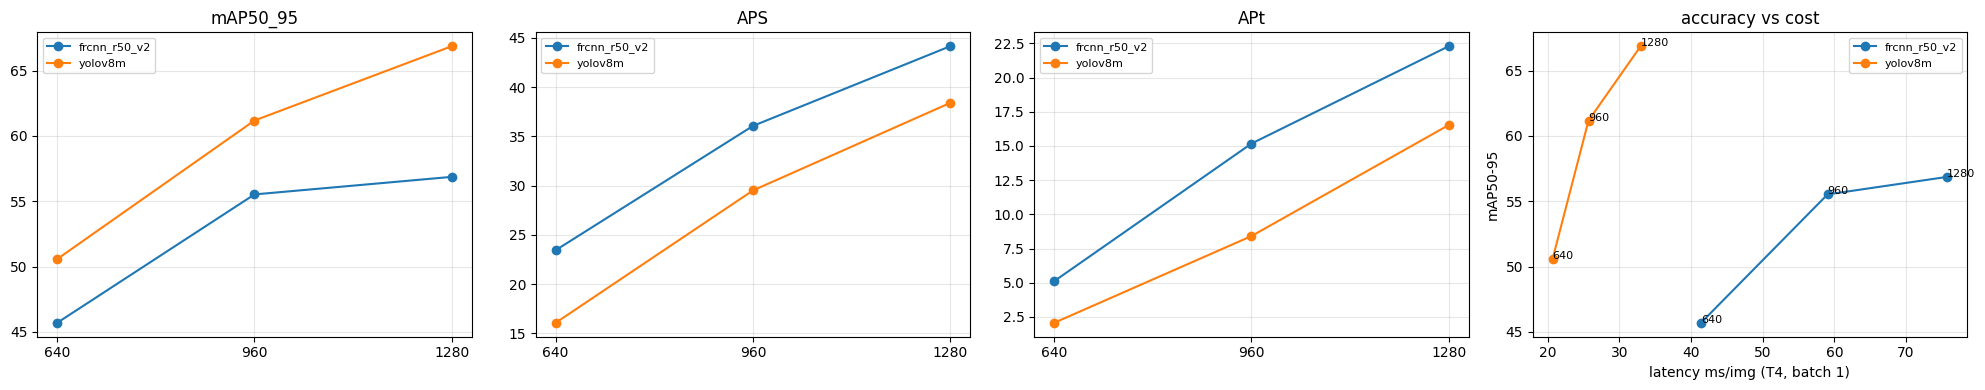

In [11]:
df = ml.results_df()
R = df[df.model_version.isin(FINALISTS) & (df.dataset_size == N_SCREEN) & (df.tiling == "none") &
       (df.pretraining == "COCO") & df.stage.isin(["S1", "S2"]) & (df.eval_split == "val") & (df.inference_mode == "full")]
R = R.sort_values(["model_version", "resolution"])
display(R[["experiment_id","stage","model_version","dataset_size","resolution","tiling","inference_mode","pretraining","mAP50_95","mAP50","APS","APt","APM","recall","F1","FPS","GPU_memory_infer_GB","parameters_M","train_time_h"] + ["GPU_memory_train_GB"]])
ml.save_table(R[["experiment_id","stage","model_version","dataset_size","resolution","tiling","inference_mode","pretraining","mAP50_95","mAP50","APS","APt","APM","recall","F1","FPS","GPU_memory_infer_GB","parameters_M","train_time_h"] + ["GPU_memory_train_GB"]], "S2_resolution")

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for m, g in R.groupby("model_version"):
    for a, met in zip(ax[:3], ["mAP50_95", "APS", "APt"]):
        a.plot(g.resolution, g[met], "o-", label=m); a.set_title(met); a.set_xticks([640, 960, 1280])
    ax[3].plot(g.latency_ms, g.mAP50_95, "o-", label=m)
    for _, r in g.iterrows():
        ax[3].annotate(int(r.resolution), (r.latency_ms, r.mAP50_95), fontsize=8)
ax[3].set_xlabel("latency ms/img (T4, batch 1)"); ax[3].set_ylabel("mAP50-95"); ax[3].set_title("accuracy vs cost")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); ml.savefig("S2_resolution.png"); plt.show()

## 4 · Decide best model and best resolution

In [12]:
cands = R.copy()
best_overall, why = ml.select_best(cands)
BEST_MODEL = best_overall.model_version
g = R[R.model_version == BEST_MODEL].sort_values("resolution")
top = g.loc[g.mAP50_95.idxmax()]
ok = g[(g.mAP50_95 >= top.mAP50_95 - 1.0) & (g.APS >= top.APS - 1.0)]
BEST_RES = int(ok.resolution.min())
ml.set_decision("best_model", BEST_MODEL, why)
ml.set_decision("best_res", BEST_RES, f"lowest resolution within 1 AP (mAP & APS) of the best: {g[['resolution','mAP50_95','APS']].to_dict('records')}")
print(BEST_MODEL, BEST_RES)

6 candidates: S2_frcnn_r50_v2_n1000_r640_full_COCO_s42, S1_frcnn_r50_v2_n1000_r960_full_COCO_s42, S2_frcnn_r50_v2_n1000_r1280_full_COCO_s42, S2_yolov8m_n1000_r640_full_COCO_s42, S1_yolov8m_n1000_r960_full_COCO_s42, S2_yolov8m_n1000_r1280_full_COCO_s42
mAP50_95: best 66.87; within 1.0 -> ['S2_yolov8m_n1000_r1280_full_COCO_s42']
SELECTED: S2_yolov8m_n1000_r1280_full_COCO_s42
DECISION best_model = yolov8m
DECISION best_res = 1280
yolov8m 1280


Write down in the report: the per-resolution gains, the extra latency/memory they cost, and whether 1280 fits the T4 at all for each model (batch actually used is in the table).